# Customer Behaviour: Exploratory Data Analysis

**Data:** cleaned Online Retail II tables (`sales` and `returns`) from `01_data_cleaning.ipynb` (run that notebook first).
**Goal:** understand how customers buy, so we can define churn and choose the snapshot dates.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

# One clean style for all charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Folder where the charts are saved (they will be used in the README)
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)


def takeaway(text):
    # Show the takeaway under a chart. The numbers in the text are computed from the data,
    # so the text always matches the data, even after the data is cleaned again.
    display(Markdown("**Takeaway:** " + text))

## Load the cleaned data

In [2]:
# Load the two tables saved by the cleaning notebook
sales = pd.read_parquet("../data/processed/sales.parquet")
returns = pd.read_parquet("../data/processed/returns.parquet")

# Revenue of each row = quantity x price
sales["line_total"] = sales["quantity"] * sales["price"]

print("Sales:", sales.shape)
print("Returns:", returns.shape)
sales.dtypes

Sales: (775278, 10)
Returns: (16285, 9)


invoice                    str
stockcode                  str
description                str
quantity                 int64
invoicedate     datetime64[us]
price                  float64
customer_id              int64
country                    str
source_sheet               str
line_total             float64
dtype: object

## Build an invoice-level table

In [3]:
# One row per invoice. A "purchase" is one invoice (one shopping trip),
# not one product line. A basket with 10 products is still 1 purchase.
invoices = (
    sales.groupby(["customer_id", "invoice"])
    .agg(invoice_date=("invoicedate", "min"), revenue=("line_total", "sum"))
    .reset_index()
)

print("Invoices:", len(invoices), "| Customers:", invoices["customer_id"].nunique())

Invoices: 36480 | Customers: 5851


## When do customers buy? Monthly activity

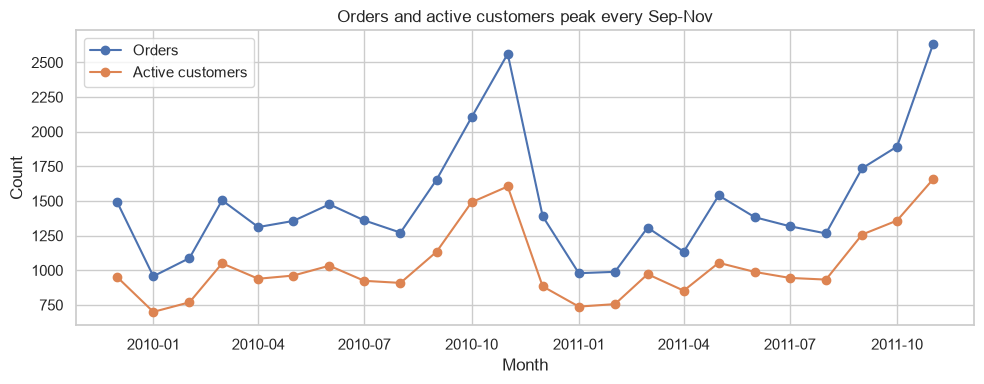

In [4]:
# Orders, active customers and revenue for each month
monthly = invoices.groupby(invoices["invoice_date"].dt.to_period("M")).agg(
    orders=("invoice", "nunique"),
    active_customers=("customer_id", "nunique"),
    revenue=("revenue", "sum"),
)

# Drop the last month: the data ends on 9 Dec 2011, so Dec 2011 is incomplete
monthly_full = monthly.iloc[:-1].copy()
monthly_full.index = monthly_full.index.to_timestamp()

fig, ax = plt.subplots()
ax.plot(monthly_full.index, monthly_full["orders"], marker="o", label="Orders")
ax.plot(monthly_full.index, monthly_full["active_customers"], marker="o", label="Active customers")
ax.set_title("Orders and active customers peak every Sep-Nov")
ax.set_xlabel("Month")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "monthly_activity.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Orders and active customers peak from September to November and fall in January-February, in both years. The test period (Sep-Dec 2011) is therefore a busy season. Dec 2011 is left out because the data ends on 9 Dec.

## How long do customers wait between purchases?

count    30629.0
mean        51.8
std         75.9
min          0.0
50%         25.0
75%         62.0
90%        136.0
95%        207.0
max        714.0
Name: days_since_prev, dtype: float64


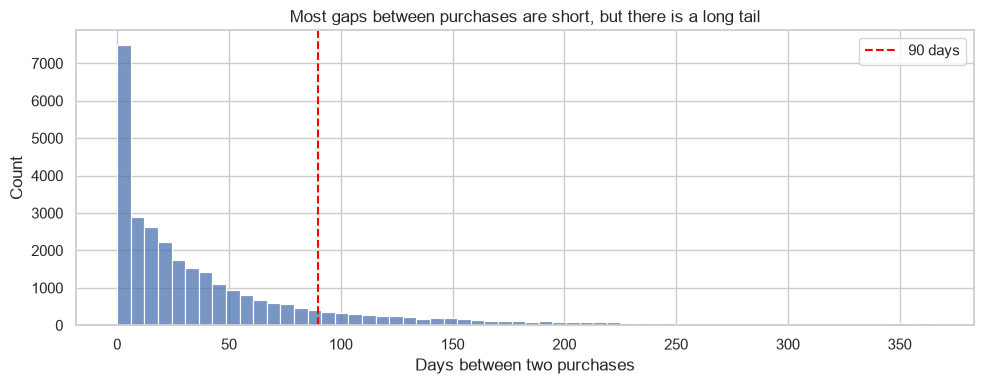

**Takeaway:** The median gap between purchases is 25 days, 75% of gaps are under 62 days and 90% under 136 days. The mean (52 days) is higher than the median because of a long tail of customers who come back late. These gaps only include customers who did come back, so the next section checks the 90-day window in a fairer way.

In [5]:
# Days between two consecutive purchases of the same customer
invoices = invoices.sort_values(["customer_id", "invoice_date"])
invoices["days_since_prev"] = invoices.groupby("customer_id")["invoice_date"].diff().dt.days

# Typical gaps: median, 75%, 90% and 95% of the gaps
print(invoices["days_since_prev"].describe(percentiles=[0.5, 0.75, 0.9, 0.95]).round(1))

# Histogram of the gaps, shown up to one year
gaps = invoices["days_since_prev"].dropna()

fig, ax = plt.subplots()
sns.histplot(gaps[gaps <= 365], bins=60, ax=ax)
ax.axvline(90, color="red", linestyle="--", label="90 days")
ax.set_title("Most gaps between purchases are short, but there is a long tail")
ax.set_xlabel("Days between two purchases")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "purchase_gaps.png", dpi=150, bbox_inches="tight")
plt.show()

p50, p75, p90 = gaps.quantile([0.5, 0.75, 0.9])
takeaway(
    f"The median gap between purchases is {p50:.0f} days, 75% of gaps are under {p75:.0f} days and 90% under {p90:.0f} days. "
    f"The mean ({gaps.mean():.0f} days) is higher than the median because of a long tail of customers who come back late. "
    "These gaps only include customers who did come back, so the next section checks the 90-day window in a fairer way."
)

## Does a 90-day churn window make sense?

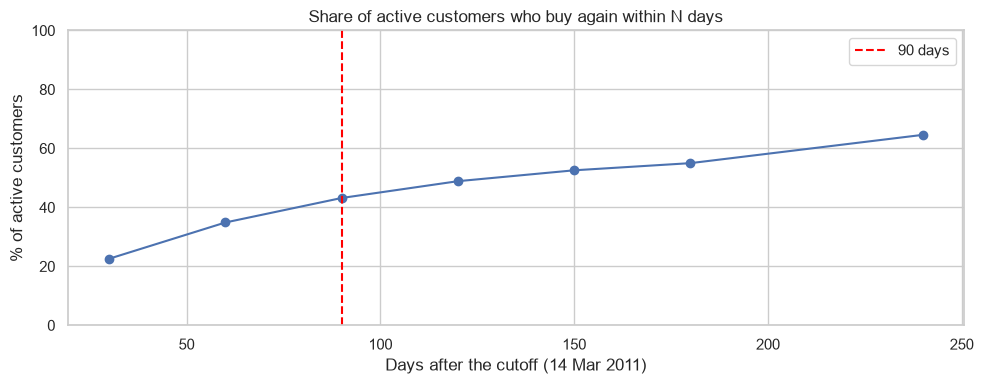

Active customers at the cutoff: 3333
30     22.6
60     34.9
90     43.2
120    48.9
150    52.6
180    55.0
240    64.6
dtype: float64


**Takeaway:** At the 14 Mar 2011 cutoff, 3,333 customers were active. 43.2% of them bought again within 90 days, 55.0% within 180 days and 64.6% within 240 days, so about 57% did not buy within 90 days. Between day 90 and day 180 another 11.8 points came back, so 90 days is a practical business choice, not a point where returns stop. We keep 90 days and test 60 and 120 days later as a sensitivity check.

In [6]:
# Use a TRAINING-period cutoff, so we do not use the valid/test periods to make design decisions
cutoff = pd.Timestamp("2011-03-14")

# Customers with at least one purchase in the 180 days before the cutoff
past = invoices[invoices["invoice_date"] < cutoff]
active = past[past["invoice_date"] >= cutoff - pd.Timedelta(days=180)]["customer_id"].unique()

# For these customers: when did they make their NEXT purchase after the cutoff?
future = invoices[(invoices["invoice_date"] >= cutoff) & (invoices["customer_id"].isin(active))]
days_to_next = (future.groupby("customer_id")["invoice_date"].min() - cutoff).dt.days

# Share of ALL active customers who came back within N days
windows = [30, 60, 90, 120, 150, 180, 240]
back_rate = pd.Series({d: (days_to_next <= d).sum() / len(active) for d in windows})

fig, ax = plt.subplots()
back_rate.mul(100).plot(ax=ax, marker="o")
ax.axvline(90, color="red", linestyle="--", label="90 days")
ax.set_title("Share of active customers who buy again within N days")
ax.set_xlabel("Days after the cutoff (14 Mar 2011)")
ax.set_ylabel("% of active customers")
ax.set_ylim(0, 100)   # full 0-100 scale so the curve is not exaggerated
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "repurchase_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print("Active customers at the cutoff:", len(active))
print((back_rate * 100).round(1))

r90, r180, r240 = back_rate[90] * 100, back_rate[180] * 100, back_rate[240] * 100
gain = r180 - r90
if gain >= 3:
    shape = f"Between day 90 and day 180 another {gain:.1f} points came back, so 90 days is a practical business choice, not a point where returns stop."
else:
    shape = f"After day 90 only {gain:.1f} more points came back by day 180, so the curve is almost flat and 90 days is a sensible window."

takeaway(
    f"At the 14 Mar 2011 cutoff, {len(active):,} customers were active. {r90:.1f}% of them bought again within 90 days, "
    f"{r180:.1f}% within 180 days and {r240:.1f}% within 240 days, so about {100 - r90:.0f}% did not buy within 90 days. "
    f"{shape} We keep 90 days and test 60 and 120 days later as a sensitivity check."
)

## How many orders does a typical customer make?

Share of one-time buyers: 27.7 %
count    5851.0
mean        6.2
std        12.7
min         1.0
25%         1.0
50%         3.0
75%         7.0
max       371.0
dtype: float64


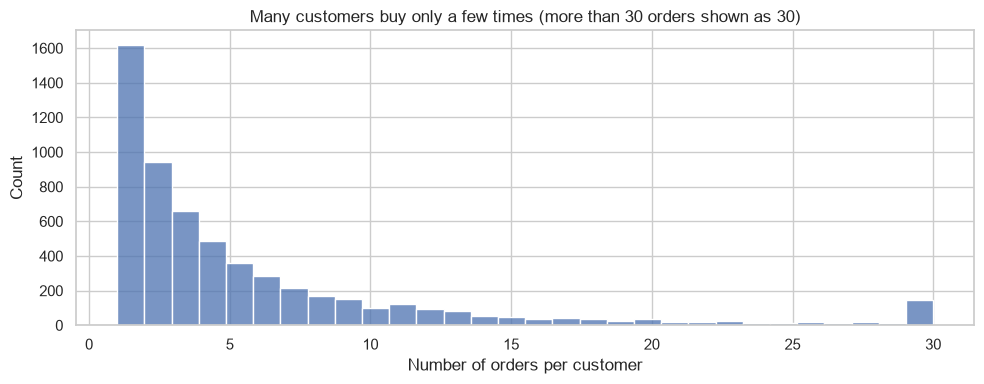

**Takeaway:** 27.7% of customers bought only once and the typical customer has 3 orders. A few customers have hundreds of orders (maximum 371), possibly wholesale customers. These very active customers can distort features later, so we will reduce their effect with log transforms.

In [7]:
orders_per_customer = invoices.groupby("customer_id").size()

one_time_pct = (orders_per_customer == 1).mean() * 100
print("Share of one-time buyers:", round(one_time_pct, 1), "%")
print(orders_per_customer.describe().round(1))

fig, ax = plt.subplots()
sns.histplot(orders_per_customer.clip(upper=30), bins=30, ax=ax)
ax.set_title("Many customers buy only a few times (more than 30 orders shown as 30)")
ax.set_xlabel("Number of orders per customer")
plt.tight_layout()
plt.savefig(fig_dir / "orders_per_customer.png", dpi=150, bbox_inches="tight")
plt.show()

max_orders = int(orders_per_customer.max())
if max_orders >= 100:
    heavy_text = (
        f"A few customers have hundreds of orders (maximum {max_orders:,}), possibly wholesale customers. "
        "These very active customers can distort features later, so we will reduce their effect with log transforms."
    )
else:
    heavy_text = f"The most active customer has {max_orders} orders."
takeaway(
    f"{one_time_pct:.1f}% of customers bought only once and the typical customer has {orders_per_customer.median():.0f} orders. "
    + heavy_text
)

## Who brings the money?

Top 10% of customers bring 63% of revenue


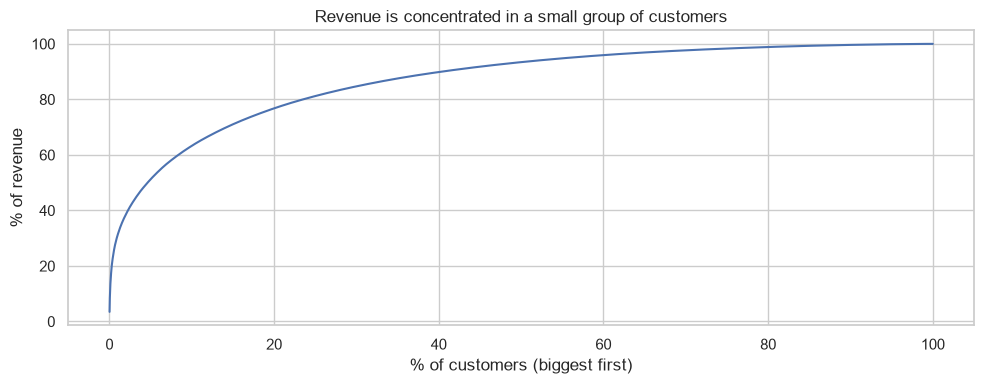

**Takeaway:** The top 10% of customers bring 63% of revenue. Losing a big customer costs far more than losing a small one, so the business decision (Step 7) must use customer value, not only churn probability.

In [8]:
# Total revenue per customer, biggest first
customer_revenue = invoices.groupby("customer_id")["revenue"].sum().sort_values(ascending=False)

# Cumulative share of revenue vs share of customers (Pareto curve)
cum_share = customer_revenue.cumsum() / customer_revenue.sum()
customer_pct = np.arange(1, len(cum_share) + 1) / len(cum_share) * 100

top10 = customer_revenue.head(int(len(customer_revenue) * 0.1)).sum() / customer_revenue.sum()
print(f"Top 10% of customers bring {top10:.0%} of revenue")

fig, ax = plt.subplots()
ax.plot(customer_pct, cum_share * 100)
ax.set_title("Revenue is concentrated in a small group of customers")
ax.set_xlabel("% of customers (biggest first)")
ax.set_ylabel("% of revenue")
plt.tight_layout()
plt.savefig(fig_dir / "revenue_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

if top10 >= 0.4:
    value_text = (
        "Losing a big customer costs far more than losing a small one, "
        "so the business decision (Step 7) must use customer value, not only churn probability."
    )
else:
    value_text = "Revenue is only moderately concentrated."
takeaway(f"The top 10% of customers bring {top10:.0%} of revenue. " + value_text)

## How big are the orders?

count    36480.0
mean       458.3
std        951.2
min          0.4
50%        302.5
90%        822.0
99%       3485.3
max      44051.6
Name: revenue, dtype: float64


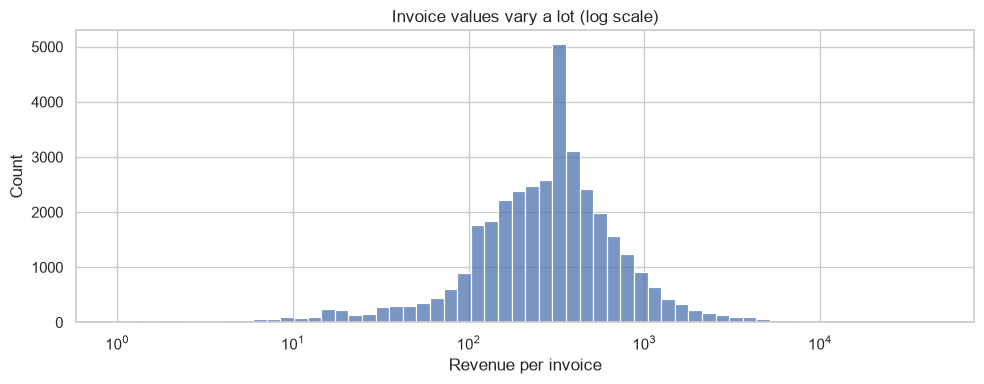

**Takeaway:** The median invoice is 302, but the 99th percentile is 3,485 and the largest invoice is 44,052. Outliers like this would distort averages, so features such as basket value will use the median or a log transform.

In [9]:
# Spread of invoice values
print(invoices["revenue"].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

fig, ax = plt.subplots()
sns.histplot(invoices["revenue"].clip(lower=1), log_scale=True, bins=60, ax=ax)
ax.set_title("Invoice values vary a lot (log scale)")
ax.set_xlabel("Revenue per invoice")
plt.tight_layout()
plt.savefig(fig_dir / "invoice_value.png", dpi=150, bbox_inches="tight")
plt.show()

inv_median = invoices["revenue"].median()
inv_p99 = invoices["revenue"].quantile(0.99)
inv_max = invoices["revenue"].max()
if inv_p99 / inv_median >= 5:
    outlier_text = "Outliers like this would distort averages, so features such as basket value will use the median or a log transform."
else:
    outlier_text = "Invoice values are fairly even, so outliers are not a big concern."
takeaway(
    f"The median invoice is {inv_median:,.0f}, but the 99th percentile is {inv_p99:,.0f} and the largest invoice is {inv_max:,.0f}. "
    + outlier_text
)

## Which countries do customers come from?

country
United Kingdom    83.4
EIRE               3.5
Netherlands        3.3
Germany            2.3
France             1.8
Australia          1.0
Spain              0.6
Switzerland        0.6
Name: line_total, dtype: float64


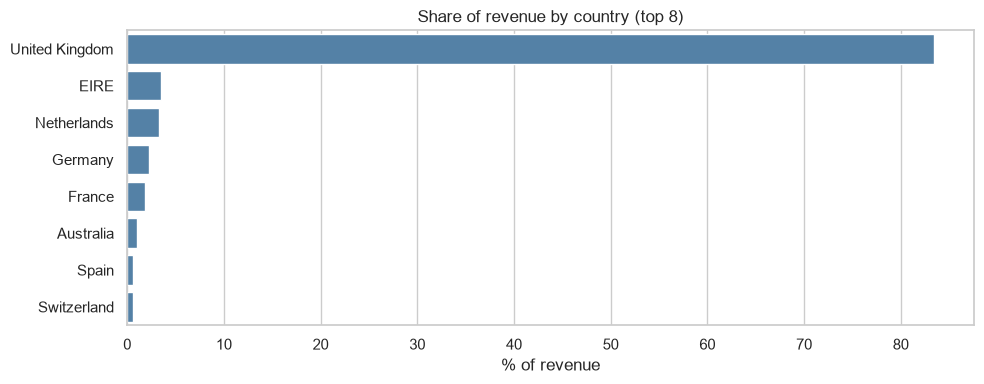

**Takeaway:** United Kingdom brings 83.4% of revenue; the next countries (EIRE 3.5%, Netherlands 3.3%) are small. We will use a simple `is_uk` feature instead of one column for every country.

In [10]:
# Share of revenue by country
country_revenue = sales.groupby("country")["line_total"].sum().sort_values(ascending=False)
country_share = (country_revenue / country_revenue.sum() * 100).round(1)

top_countries = country_share.head(8)
print(top_countries)

fig, ax = plt.subplots()
sns.barplot(x=top_countries.values, y=top_countries.index, ax=ax, color="steelblue")
ax.set_title("Share of revenue by country (top 8)")
ax.set_xlabel("% of revenue")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(fig_dir / "country_share.png", dpi=150, bbox_inches="tight")
plt.show()

first = top_countries.index[0]
others = ", ".join(f"{name} {share:.1f}%" for name, share in top_countries.iloc[1:3].items())
if top_countries.iloc[0] > 70:
    country_text = (
        f"{first} brings {top_countries.iloc[0]:.1f}% of revenue; the next countries ({others}) are small. "
        "We will use a simple `is_uk` feature instead of one column for every country."
    )
else:
    country_text = f"No single country dominates: {first} brings {top_countries.iloc[0]:.1f}% of revenue, then {others}."
takeaway(country_text)

## How important are returns?

In [11]:
# Return value (quantity is negative in returns, so take the absolute value)
returns["return_value"] = (returns["quantity"] * returns["price"]).abs()

return_share = returns["return_value"].sum() / sales["line_total"].sum() * 100
print("Returns value as % of sales value:", round(return_share, 1))

# Customers with at least one return, among customers who have real purchases
returners = returns[returns["customer_id"].isin(invoices["customer_id"])]["customer_id"].nunique()
returners_pct = returners / invoices["customer_id"].nunique()
print("Customers with at least one return:", returners, f"({returners_pct:.0%})")

if returners_pct >= 0.2:
    return_text = 'Returns are common, so a "return rate" feature is worth building.'
else:
    return_text = "Returns are not very common, so a return rate feature may add little."
takeaway(
    f"Returns are {return_share:.1f}% of sales value, and {returners:,} customers ({returners_pct:.0%}) made at least one return. "
    + return_text
)

Returns value as % of sales value: 2.2
Customers with at least one return: 2335 (40%)


**Takeaway:** Returns are 2.2% of sales value, and 2,335 customers (40%) made at least one return. Returns are common, so a "return rate" feature is worth building.

## Are many invoices placed on the same day?

In [12]:
# Share of gaps that are exactly 0 days (a second invoice on the same day)
same_day_pct = (gaps == 0).mean() * 100
print("Same-day gaps:", round(same_day_pct, 1), "%")

takeaway(
    f"{same_day_pct:.1f}% of the gaps between purchases are 0 days (a second invoice on the same day), "
    "so one shopping trip is sometimes split into several invoices. Frequency features will count both invoices and distinct purchase days."
)

Same-day gaps: 13.1 %


**Takeaway:** 13.1% of the gaps between purchases are 0 days (a second invoice on the same day), so one shopping trip is sometimes split into several invoices. Frequency features will count both invoices and distinct purchase days.

## Is the biggest invoice a real purchase?

In [13]:
# The 3 biggest invoices after cleaning
big = invoices.sort_values("revenue", ascending=False).head(3)
print(big[["customer_id", "invoice", "invoice_date", "revenue"]])

# Lines of the biggest invoice
top = big.iloc[0]
sales[sales["invoice"] == top["invoice"]][["invoice", "stockcode", "description", "quantity", "price", "invoicedate"]].head(10)

       customer_id invoice        invoice_date  revenue
11071        14156  493819 2010-01-07 12:34:00  44051.6
17498        15098  556444 2011-06-10 15:28:00  38970.0
31109        17450  524181 2010-09-27 16:59:00  33167.8


,invoice,stockcode,description,quantity,price,invoicedate
32277,493819,21912,VINTAGE SNAKES & LADDERS,216,3.39,2010-01-07 12:34:00
32278,493819,21749,LARGE RED SPOT WINDMILL,288,1.85,2010-01-07 12:34:00
32279,493819,21974,SET OF 36 PAISLEY FLOWER DOILIES,288,1.25,2010-01-07 12:34:00
32280,493819,21877,HOME SWEET HOME MUG,288,1.06,2010-01-07 12:34:00
32281,493819,21746,SMALL RED SPOT WINDMILL,192,1.06,2010-01-07 12:34:00
32282,493819,21843,RETRO SPOT CAKE STAND,144,10.95,2010-01-07 12:34:00
32283,493819,47502,POLKADOT CUTLERY 24 PCS IN TRAY,200,9.95,2010-01-07 12:34:00
32284,493819,84968D,S/16 VINTAGE RED CUTLERY,96,10.95,2010-01-07 12:34:00
32285,493819,84968C,S/16 VINTAGE PISTACHIO CUTLERY,96,10.95,2010-01-07 12:34:00
32286,493819,85123A,WHITE HANGING HEART T-LIGHT HOLDER,160,2.55,2010-01-07 12:34:00


In [14]:
# Cancellations of the same customer within 30 days after the biggest invoice
near_returns = returns[
    (returns["customer_id"] == top["customer_id"])
    & (returns["invoicedate"] >= top["invoice_date"])
    & (returns["invoicedate"] <= top["invoice_date"] + pd.Timedelta(days=30))
][["invoice", "stockcode", "description", "quantity", "price", "invoicedate"]]
display(near_returns.head(10))

# In the first pass the biggest invoice was 581483, cancelled 12 minutes later
still_there = (sales["invoice"] == "581483").any()
takeaway(
    f"After cleaning, the largest invoice is {top['revenue']:,.0f} (customer {top['customer_id']}). "
    "In the first pass the largest invoice (581483, 168,470) had been cancelled 12 minutes later; "
    f"it is {'STILL in' if still_there else 'no longer in'} the sales table. "
    f"This customer has {len(near_returns)} cancellation line(s) within 30 days after the largest invoice."
)

,invoice,stockcode,description,quantity,price,invoicedate
997,C493852,21257,VICTORIAN SEWING BOX MEDIUM,-1,6.60,2010-01-07 15:50:00
1189,C494973,20726,LUNCH BAG WOODLAND,-50,1.45,2010-01-20 11:06:00
1190,C494973,20715,LITTLE FLOWER SHOPPER BAG,-400,1.06,2010-01-20 11:06:00


**Takeaway:** After cleaning, the largest invoice is 44,052 (customer 14156). In the first pass the largest invoice (581483, 168,470) had been cancelled 12 minutes later; it is no longer in the sales table. This customer has 3 cancellation line(s) within 30 days after the largest invoice.

## Are there non-product rows (postage, fees)?

In [15]:
# Rows whose stock code does not start with 5 digits (normal products do)
non_product = sales[~sales["stockcode"].str.match(r"^\d{5}")]
print("Rows with a stock code that does not start with 5 digits:", len(non_product))

display(
    non_product.groupby(["stockcode", "description"]).agg(
        rows=("invoice", "size"), revenue=("line_total", "sum")
    ).sort_values("revenue", ascending=False).head(15)
)

takeaway(
    f"{len(non_product):,} rows still have a stock code that does not start with 5 digits. "
    "If the table above only shows real products (such as SP1002 or PADS), the postage, manual, fee and adjustment rows are gone."
)

Rows with a stock code that does not start with 5 digits: 19


,,rows,revenue
stockcode,description,,
SP1002,KID'S CHALKBOARD/EASEL,2,14.750
PADS,PADS TO MATCH ALL CUSHIONS,17,0.017


**Takeaway:** 19 rows still have a stock code that does not start with 5 digits. If the table above only shows real products (such as SP1002 or PADS), the postage, manual, fee and adjustment rows are gone.

## Is the 90-day curve stable across cutoffs?

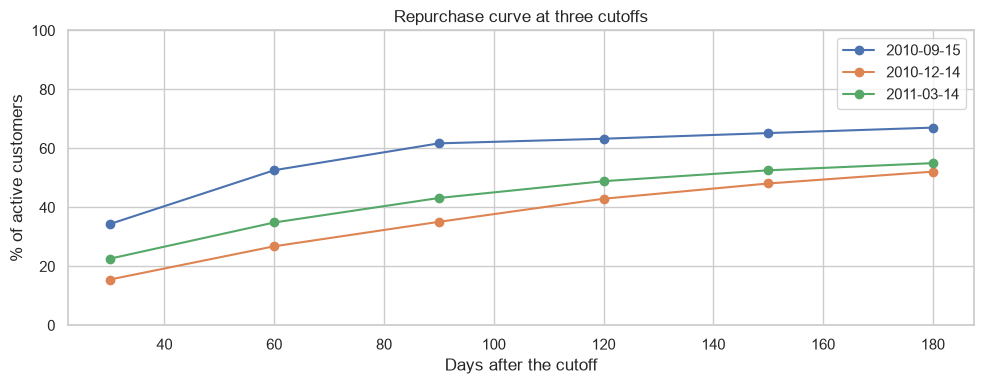

     2010-09-15  2010-12-14  2011-03-14
30         34.3        15.5        22.6
60         52.6        26.8        34.9
90         61.7        35.1        43.2
120        63.3        42.9        48.9
150        65.2        48.1        52.6
180        67.0        52.1        55.0


**Takeaway:** At 90 days, 62% of active customers bought again at the 15 Sep 2010 cutoff, 35% at 14 Dec 2010 and 43% at 14 Mar 2011 (churn by this definition: 38%, 65% and 57%). The repurchase rate depends strongly on the season. This suggests that many customers pause in the quiet season and return later, so a 90-day gap mixes real churn with seasonal pauses. The test snapshot (Sep-Dec 2011) is in the busy season, so its churn rate may be lower than in some train snapshots. We will compare snapshots with lift and ranking metrics, not raw PR-AUC.

In [16]:
# Same repurchase curve at three TRAINING cutoffs (the valid and test periods are not touched).
# A function is used because the same logic runs three times.
def repurchase_curve(cutoff, windows=(30, 60, 90, 120, 150, 180)):
    cutoff = pd.Timestamp(cutoff)
    past = invoices[invoices["invoice_date"] < cutoff]
    active = past[past["invoice_date"] >= cutoff - pd.Timedelta(days=180)]["customer_id"].unique()
    future = invoices[(invoices["invoice_date"] >= cutoff) & (invoices["customer_id"].isin(active))]
    days_to_next = (future.groupby("customer_id")["invoice_date"].min() - cutoff).dt.days
    return pd.Series({d: (days_to_next <= d).sum() / len(active) * 100 for d in windows})


curves = pd.DataFrame({c: repurchase_curve(c) for c in ["2010-09-15", "2010-12-14", "2011-03-14"]})

ax = curves.plot(marker="o")
ax.set_title("Repurchase curve at three cutoffs")
ax.set_xlabel("Days after the cutoff")
ax.set_ylabel("% of active customers")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig(fig_dir / "repurchase_curve_cutoffs.png", dpi=150, bbox_inches="tight")
plt.show()

print(curves.round(1))

c_sep, c_dec, c_mar = curves.loc[90, "2010-09-15"], curves.loc[90, "2010-12-14"], curves.loc[90, "2011-03-14"]
spread = curves.loc[90].max() - curves.loc[90].min()
if spread > 10:
    season_note = (
        "depends strongly on the season. This suggests that many customers pause in the quiet season and return later, "
        "so a 90-day gap mixes real churn with seasonal pauses. The test snapshot (Sep-Dec 2011) is in the busy season, "
        "so its churn rate may be lower than in some train snapshots. We will compare snapshots with lift and ranking metrics, not raw PR-AUC."
    )
else:
    season_note = "is fairly stable across seasons. The 90-day choice looks robust."

season_first = season_note.split(".")[0]   # first sentence only, used in the Findings

takeaway(
    f"At 90 days, {c_sep:.0f}% of active customers bought again at the 15 Sep 2010 cutoff, {c_dec:.0f}% at 14 Dec 2010 and {c_mar:.0f}% at 14 Mar 2011 "
    f"(churn by this definition: {100 - c_sep:.0f}%, {100 - c_dec:.0f}% and {100 - c_mar:.0f}%). The repurchase rate {season_note}"
)

## Findings

In [17]:
# Findings are built from the numbers computed above, so they always match the data
display(Markdown(f"""
- Strong seasonality: orders peak in Sep-Nov and drop in Jan-Feb. Dec 2011 is partial, so it is excluded from the charts.
- Median gap between purchases is {p50:.0f} days; 75% of gaps are under {p75:.0f} days and 90% under {p90:.0f} days. {same_day_pct:.1f}% of gaps are same-day invoices.
- {one_time_pct:.1f}% of customers bought only once; the typical customer has {orders_per_customer.median():.0f} orders.
- Repurchase curve (cutoff 14 Mar 2011): {r90:.1f}% of active customers buy again within 90 days and {r180:.1f}% within 180 days.
- The repurchase rate within 90 days is {c_sep:.0f}% / {c_dec:.0f}% / {c_mar:.0f}% at the 15 Sep 2010 / 14 Dec 2010 / 14 Mar 2011 cutoffs, so it {season_first}.
- Top 10% of customers bring {top10:.0%} of revenue.
- {first} brings {top_countries.iloc[0]:.1f}% of revenue.
- Returns are {return_share:.1f}% of sales value; {returners_pct:.0%} of customers made at least one return.
- Decision: churn = no purchase in the next 90 days, scored only for customers active in the last 180 days. Sensitivity checks with 60 and 120 days come later.
"""))


- Strong seasonality: orders peak in Sep-Nov and drop in Jan-Feb. Dec 2011 is partial, so it is excluded from the charts.
- Median gap between purchases is 25 days; 75% of gaps are under 62 days and 90% under 136 days. 13.1% of gaps are same-day invoices.
- 27.7% of customers bought only once; the typical customer has 3 orders.
- Repurchase curve (cutoff 14 Mar 2011): 43.2% of active customers buy again within 90 days and 55.0% within 180 days.
- The repurchase rate within 90 days is 62% / 35% / 43% at the 15 Sep 2010 / 14 Dec 2010 / 14 Mar 2011 cutoffs, so it depends strongly on the season.
- Top 10% of customers bring 63% of revenue.
- United Kingdom brings 83.4% of revenue.
- Returns are 2.2% of sales value; 40% of customers made at least one return.
- Decision: churn = no purchase in the next 90 days, scored only for customers active in the last 180 days. Sensitivity checks with 60 and 120 days come later.
